# Experiment 02: Building identity

Card: [exp02_building.md](../../experiments/exp02_building.md)


In [16]:
import os
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, METERS, MODEL_COLORS
from ashrae.data import read_processed, split
from ashrae.features import add_series_mean, build_features
from ashrae.metrics import rmsle, rmsle_by_meter
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp02_building"
if SMOKE:
    EXPERIMENT = "ashrae-mlp-building-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 2
    REFERENCE = (
        "ashrae-mlp-outputs-smoke",
        None,
        "mlp_4out",
    )  # None: the latest session
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-building"
    TRAIN = True  # after the full run, set False and SESSION to its timestamp
    SESSION = None
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 10
    REFERENCE = ("ashrae-mlp-outputs", "2026-10-12 10:53:33", "mlp_4out")
    FIGURE = "../../figures/exp02_building.png"
# mlp_4out is reused from exp01
NETS = ["mlp_4out_mean", "mlp_4out_emb"]
MODELS = [REFERENCE[2], *NETS]
# lgbm_building from baseline exp01, the baseline kept in baseline/baseline_report.md
BASELINE = ("ashrae-baseline-building", "2026-10-11 11:16:15", "lgbm_building")

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

2026/10/12 12:03:22 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-building' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-building', session 2026-10-12 12:03:22


## Training


In [17]:
def scores(y, pred, meter, anomaly):
    """Validation RMSLE on all rows (overall and per meter) and on clean rows."""
    return {
        **rmsle_by_meter(y, pred, meter),
        "val_rmsle_clean": rmsle(y[~anomaly], pred[~anomaly]),
    }


if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        X_train_sm, X_val_sm = add_series_mean(
            X_train, train_df, train_df
        ), add_series_mean(X_val, val_df, train_df)
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "loaders_sm": make_loaders(train_df, val_df, X_train_sm, X_val_sm)[:2],
            "y_val": np.log1p(val_df.meter_reading.to_numpy(dtype="float32")),
            "meter": val_df.meter.to_numpy(),
            "anomaly": val_df.anomaly.to_numpy(),
        }
    del df
    n_features = X_train.shape[1]
    make = {  # name: (network, whether it gets the series mean as an input)
        "mlp_4out_mean": (lambda: MeterMLP(n_features + 1), True),
        "mlp_4out_emb": (lambda: MeterMLP(n_features, n_buildings), False),
    }
    for fold, d in folds.items():
        for name in NETS:
            make_net, series_mean = make[name]
            train_loader, val_loader = d["loaders_sm" if series_mean else "loaders"]
            model, run_id = experiment.fit(
                make_net,
                train_loader,
                val_loader,
                run_name=f"{name} | {fold}",
                epochs=EPOCHS,
                tags={"fold": fold, "model": name},
                params={"n_train": N_TRAIN, "n_val": N_VAL},
            )
            s = scores(d["y_val"], predict(model, val_loader), d["meter"], d["anomaly"])
            # Lightning already logged the overall val_rmsle per epoch
            experiment.log_metrics(
                run_id, {k: v for k, v in s.items() if k != "val_rmsle"}
            )

mlp_4out_mean | Jan–Mar: 100%|██████████| 4890/4890 [00:19<00:00, 252.68batch/s, epoch 10, val 1.4631, best 1.4595 at 8]
mlp_4out_emb | Jan–Mar: 100%|██████████| 4890/4890 [00:18<00:00, 271.59batch/s, epoch 10, val 1.4197, best 1.4197 at 10]
mlp_4out_mean | Apr–Jun: 100%|██████████| 4890/4890 [00:15<00:00, 314.21batch/s, epoch 10, val 1.2608, best 1.2587 at 9]
mlp_4out_emb | Apr–Jun: 100%|██████████| 4890/4890 [00:18<00:00, 257.64batch/s, epoch 10, val 1.2233, best 1.2233 at 10]
mlp_4out_mean | Jul–Sep: 100%|██████████| 4890/4890 [00:17<00:00, 280.29batch/s, epoch 10, val 1.1566, best 1.1566 at 10]
mlp_4out_emb | Jul–Sep: 100%|██████████| 4890/4890 [00:18<00:00, 266.12batch/s, epoch 10, val 1.0527, best 1.0527 at 10]
mlp_4out_mean | Oct–Dec: 100%|██████████| 4890/4890 [00:18<00:00, 269.34batch/s, epoch 10, val 1.1225, best 1.1225 at 10]
mlp_4out_emb | Oct–Dec: 100%|██████████| 4890/4890 [00:17<00:00, 273.87batch/s, epoch 10, val 1.1051, best 1.1051 at 10]


## Results


In [18]:
def reference_runs(experiment_name, session, model):
    """Runs of `model` from another notebook's session (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[experiment_name], filter_string=f"tags.model = '{model}'"
    )
    return runs[runs["tags.session"] == (session or runs["tags.session"].max())]


runs = pd.concat(
    [experiment.runs(), reference_runs(*REFERENCE), reference_runs(*BASELINE)]
)
results = runs.rename(
    columns=lambda c: c.removeprefix("metrics.").removeprefix("tags.")
)
results = results[results.fold.isin(FOLD_NAMES)]
print(
    f"MLflow session {experiment.session}: {len(results)} runs, with {REFERENCE[2]} and {BASELINE[2]}"
)

ROWS = [*MODELS, BASELINE[2]]
table = results.pivot(index="model", columns="fold", values="val_rmsle").loc[
    ROWS, FOLD_NAMES
]
averages = results.groupby("model")[
    ["val_rmsle", "val_rmsle_clean", "train_rmsle"]
].mean()
table["average"] = averages.val_rmsle
table["average, clean rows"] = averages.val_rmsle_clean
table["training"] = averages.train_rmsle  # MLPs: last epoch
display(table.round(3).rename_axis("RMSLE, all rows unless noted"))

meters = (
    results.groupby("model")[[f"val_rmsle_{name}" for name in METERS.values()]]
    .mean()
    .loc[ROWS]
)
display(
    meters.rename(columns=lambda c: c.removeprefix("val_rmsle_"))
    .round(3)
    .rename_axis("fold average, all rows")
)

MLflow session 2026-10-12 12:03:22: 16 runs, with mlp_4out and lgbm_building


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",training
"RMSLE, all rows unless noted",,,,,,,
mlp_4out,1.698,1.584,1.484,1.419,1.546,1.369,1.331
mlp_4out_mean,1.463,1.261,1.157,1.122,1.251,1.000,0.894
mlp_4out_emb,1.420,1.223,1.053,1.105,1.200,0.934,0.826
lgbm_building,1.434,1.231,1.087,1.116,1.217,0.959,0.815


,electricity,chilledwater,steam,hotwater
"fold average, all rows",,,,
mlp_4out,1.158,1.881,2.106,1.972
mlp_4out_mean,0.960,1.483,1.634,1.642
mlp_4out_emb,0.957,1.386,1.525,1.567
lgbm_building,0.975,1.392,1.560,1.583


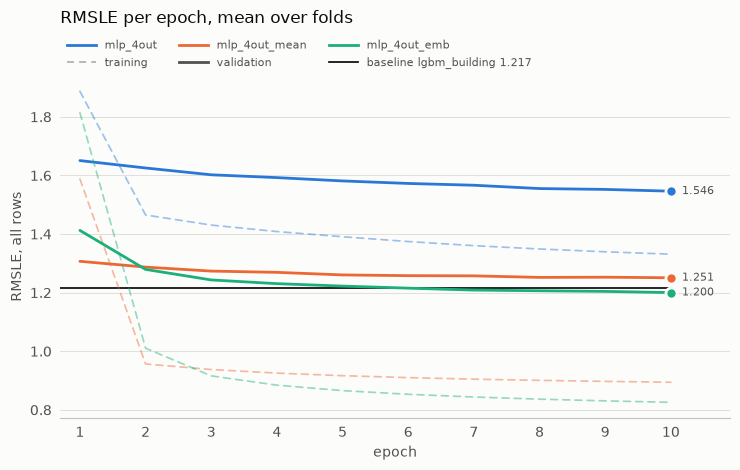

In [19]:
epochs = np.arange(1, EPOCHS + 1)
# split: (label, line style, width, alpha); training is context, so it recedes behind validation
SPLITS = {
    "train_rmsle": ("training", (0, (4, 3)), 1.25, 0.45),
    "val_rmsle": ("validation", "-", 2, 1),
}
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
curves = {
    (name, key): np.mean(
        [experiment.history(r, key) for r in results[results.model == name].run_id],
        axis=0,
    )
    for name in MODELS
    for key in SPLITS
}
baseline = averages.val_rmsle[BASELINE[2]]

fig, ax = plt.subplots(figsize=(7.5, 4.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
# LightGBM has no epochs: its fold-average validation score as a reference line, clear of the end labels
ax.hlines(baseline, 0.7, epochs[-1], color=INK, lw=1.25, zorder=1)
for (name, key), curve in curves.items():
    _, style, width, alpha = SPLITS[key]
    ax.plot(
        epochs,
        curve,
        color=MODEL_COLORS[name],
        ls=style,
        lw=width,
        alpha=alpha,
        solid_capstyle="round",
        dash_capstyle="round",
    )
    if (
        key == "val_rmsle"
    ):  # end marker and direct label on validation only; the table above has the rest
        ax.plot(
            epochs[-1],
            curve[-1],
            "o",
            ms=8,
            color=MODEL_COLORS[name],
            mec=SURFACE,
            mew=2,
        )
        ax.annotate(
            f"{curve[-1]:.3f}",
            (epochs[-1], curve[-1]),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
            color=TEXT,
        )
ax.set(
    xlabel="epoch",
    xticks=epochs,
    xlim=(0.7, epochs[-1] + 0.9),
    ylabel="RMSLE, all rows",
)
ax.set_title("RMSLE per epoch, mean over folds", loc="left", color=INK, pad=38)
ax.grid(axis="y", color=GRID, lw=0.75)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
ax.xaxis.label.set_color(TEXT)
ax.yaxis.label.set_color(TEXT)
# Legend in two rows under the title: the models, then the splits and the baseline
models = [Line2D([], [], color=MODEL_COLORS[name], lw=2, label=name) for name in MODELS]
others = [
    Line2D([], [], color=TEXT, ls=style, lw=width, alpha=alpha, label=label)
    for label, style, width, alpha in SPLITS.values()
]
others.append(
    Line2D([], [], color=INK, lw=1.25, label=f"baseline {BASELINE[2]} {baseline:.3f}")
)
handles = [
    h for pair in zip(models, others) for h in pair
]  # legend fills column by column
ax.legend(
    handles=handles,
    ncol=3,
    frameon=False,
    fontsize=8,
    handlelength=2.6,
    labelcolor=TEXT,
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    borderaxespad=0.2,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results[results.model.isin(NETS)].run_id:  # this notebook's runs only
        experiment.client.log_artifact(run_id, FIGURE)